## **[실습 1-1] Linear Regression 모델 생성, 학습, 예측**

### **1. 데이터 생성**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

**Q1. 아래의 4개의 점을 가진 데이터를 하드코딩하여 생성한다.**
```
(2,2), (3,4), (4,6), (6,7)
```
이 데이터의 X값은 독립변수, y값은 종속변수 (정답) 이라고 가정한다.

In [ ]:
#code here
x = np.array([2, 3, 4, 6])
y = np.array([2, 4, 6, 7])

### **2. 데이터 시각화**

**Q1. 생성된 4개의 점을 scatterplot으로 시각화한다.**

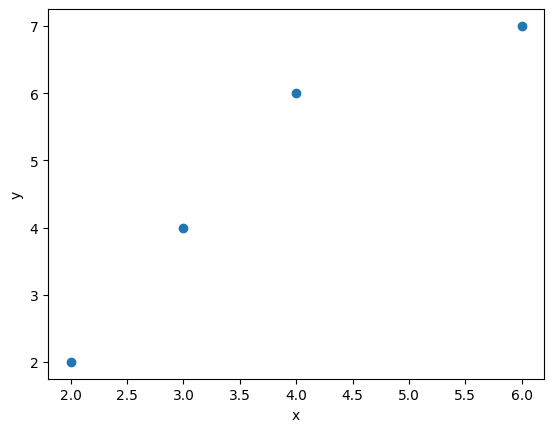

In [ ]:
#code here
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

### **3. 모델 생성하기**

**Q1. LinearRegression class를 생성한다.**

- OLS (Orinary Least Squares) 공식을 응용하여 w(coefficient), b(intercept)를 구한다.

In [ ]:
#code here
class LinearRegression:
  def __init__(self):
    self.w = None
    self.b = None

  # OLS: Find the line of best fit
  def fit(self, x, y):
    X = np.asarray(x, dtype=float)
    Y = np.asarray(y, dtype=float)
    x_mean, y_mean = np.mean(X), np.mean(Y)
    self.w = np.sum((X - x_mean) * (Y - y_mean)) / np.sum(np.square(X - x_mean))
    self.b = y_mean - self.w * x_mean
    return self

  def predict(self, x):
   X = np.asarray(x, dtype=float)
   return self.w * X + self.b

### **4. 학습하기**

**Q. 위에서 만들어진 Linear Regression 모델의 instance를 생성한다.**

그리고 생성한 X, y 데이터를 활용하여 학습시킨다.

In [ ]:
#code here
model = LinearRegression()
model.fit(x, y) # 학습

### **5. 예측하기**

**학습이 완료된 모델에 다시 X 데이터를 넣어 결과를 예측한다.**

결과는 y_pred (y_예측)이라는 변수에 저장하고, 출력해자.

In [ ]:
#code here
y_pred = model.predict(x)
print(y_pred)
print(f"y = {y}")

[2.6        3.82857143 5.05714286 7.51428571]
y = [2 4 6 7]


### **6. 결과 시각화하기**

**기존에 시각화했던 scatterplot에 model이 학습한 Line of Best Fit을 그려보자.**
- Line of Best Fit의 색은 빨간색으로, 파선으로 그린다.
- label은 "Line of Best Fit"이라고 하여, plot내에 나타나도록 해보자.

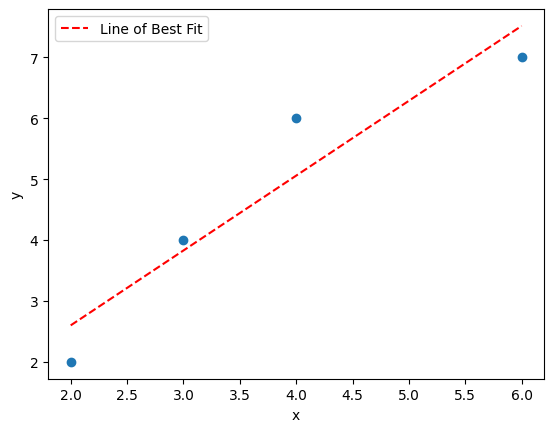

In [ ]:
#code here
plt.scatter(x, y)
plt.plot(x, y_pred, color='red', linestyle="dashed", label="Line of Best Fit")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

## **실습[1-2] 모델 평가하기**

**Q1. MAE (Mean Absolute Error) 함수 작성하기**

MAE 함수를 작성하고, 모델 성능을 평가한다.

In [ ]:
# code here
def mae(y_true, y_pred):
  y_true, y_pred = np.array(y_true), np.array(y_pred)
  return np.mean(np.abs(y_true - y_pred))

**Q2. MSE (Mean Squared Error) 함수 작성하기**

MSE 함수를 작성하고, 모델 성능을 평가한다.

In [ ]:
# code here
def mse(y_true, y_pred):
  y_true, y_pred = np.array(y_true), np.array(y_pred)
  return np.mean(np.square(y_true - y_pred))

**Q3. RMSE (Root Mean Squared Error) 함수 작성하기**

RMSE 함수를 작성하고, 모델 성능을 평가한다.

In [ ]:
# code here
def rmse(y_true, y_pred):
  return np.sqrt(mse(y_true, y_pred))

**4. r2_score 함수 작성하기**

r2_score 함수를 작성하고, 모델 성능을 평가한다.

In [ ]:
# code here
def r2_score(y_true, y_pred):
  y_true, y_pred = np.array(y_true), np.array(y_pred)
  mean_true = np.mean(y_true)
  ss_res = np.sum(np.square(y_true - y_pred)) # 모델이 설명하지 못한 오차
  ss_tot = np.sum(np.square(y_true - mean_true)) # 평균으로만 예측했을때의 오차
  return 1 - (ss_res / ss_tot)

**5. 모든 결과 출력**

MAE : ...<br>
MSE : ...<br>
RMSE : ...<br>
R2-score : ...<br>

의 형태로 출력한다.

In [ ]:
# code here
print(f"MAE : {mae(y, y_pred)}")
print(f"MSE : {mse(y, y_pred)}")
print(f"RMSE : {rmse(y, y_pred)}")
print(f"R2-score : {r2_score(y, y_pred)}")

MAE : 0.5571428571428572
MSE : 0.3857142857142857
RMSE : 0.6210590034081188
R2-score : 0.8953995157384989
